# DINOv3 hierarchical classifier, variant A: linear head on frozen features

Two logits on one linear layer, both trained with BCE on cached DINOv3 features:
1. **Stage 1:** is this a problem? Obstacle and SurfaceProblem are problems; everything else is clean.
2. **Stage 2:** given a problem, is it an Obstacle? Trained and scored on true problem images only.

Reads a processed dataset built by `scripts/build_proc_sidewalk_data_A.py`, evaluates on `pitt-val`, and for chosen configurations, on `pitt-test`. Needs a GPU runtime and an `HF_TOKEN` Colab secret. Results are on the Colab VM and will be written to the user's Google Drive.

In [20]:
!pip install -q -U transformers

import torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (switch runtime to GPU)")

torch 2.11.0+cu130 | transformers 5.22.1
GPU: NVIDIA A100-SXM4-40GB


## Config

`BASE` holds the defaults. `SWEEPS` is a list of dicts of ranges: each dict expands to all its combinations, and any
`BASE` key can be swept by adding it to a dict. `TRAIN_PLANS` lists `(split, steps)` phases, run in order.
`THRESHOLDS` are not swept here: they are applied to each trained head's saved probabilities after training.

In [21]:
from pathlib import Path

# Data
DATA_REPO = "gvadhul/sidewalk-proc-A-naive-merged-nulls"                      # private Hugging Face dataset repo holding DATA_TAR, e.g. "user/sidewalk-proc"
DATA_TAR = "proc-sidewalk-data-naive-merged-nulls.tar"
DATA_ROOT = Path("/content/proc-sidewalk-data-naive-merged-nulls")
CACHE_BATCH_SIZE = 256

# Labels: decided here, not in the processed dataset
PROBLEM_CLASSES = ["Obstacle", "SurfaceProblem"]
CLEAN_CLASSES = ["Crosswalk", "CurbRamp", "no_obstacles", "no_obstacles_manual_collection"]
EVAL_SPLIT = "pitt-val"
TEST_SPLIT = "pitt-test"
EVAL_DROP = []
K = 46                                # stage 1 Recall@K
THRESHOLD = 0.5                       # used during training; the results below use THRESHOLDS
THRESHOLDS = [0.3, 0.5, 0.7]          # stage 1 and stage 2 grid

TRAIN_PLANS = {
    "pitt": [("pitt-train", 5000)],
    "other_then_pitt": [("other-cities-train", 5000), ("pitt-train", 5000)],
}

BASE = dict(
    base_model="facebook/dinov3-vitb16-pretrain-lvd1689m",
    pooling="cls",                    # "cls", "mean" (of patch tokens) or "cls+mean"
    train="pitt",                     # a TRAIN_PLANS key
    lr=1e-4,
    batch_size=64,
    eval_every=250,
    seed=0,
)

SWEEPS = [
    dict(train=["pitt", "other_then_pitt"], lr=[1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2], weight_decay = [0.0, 1e-2], seed=[0, 1, 2]),
]

In [22]:
from itertools import product

def expand(sweeps, base):
    return [{**base, **dict(zip(s, values))} for s in sweeps for values in product(*s.values())]

CONFIGS = expand(SWEEPS, BASE)
GROUP = list(dict.fromkeys(k for s in SWEEPS for k in s if k != "seed"))  # what results average seeds over
COMPARE = [k for k in GROUP if k != "lr"]                                  # each of these gets its own lr and thresholds
print(len(CONFIGS), "runs")

84 runs


## Data

In [ ]:
import tarfile, time
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
from huggingface_hub import hf_hub_download
from PIL import Image
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except ImportError:
    HF_TOKEN = None

# drive.mount() kills the kernel under the Colab VS Code extension, so the dataset comes from Hugging Face.
if not DATA_ROOT.exists():
    t0 = time.perf_counter()
    tar = hf_hub_download(DATA_REPO, DATA_TAR, repo_type="dataset", token=HF_TOKEN)
    with tarfile.open(tar) as f:
        f.extractall(DATA_ROOT.parent, filter="data")
    print(f"downloaded and extracted in {time.perf_counter() - t0:.0f}s")

def load_split(split):
    df = pd.read_csv(DATA_ROOT / f"{split}.csv", low_memory=False)[["filename", "class", "image_path", "split", "is_frame", "source_class"]]
    if split in (EVAL_SPLIT, TEST_SPLIT):
        df = df[~df["class"].isin(EVAL_DROP)].reset_index(drop=True)
    unknown = set(df["class"]) - set(PROBLEM_CLASSES) - set(CLEAN_CLASSES)
    assert not unknown, unknown
    df["is_problem"] = df["class"].isin(PROBLEM_CLASSES)
    df["is_obstacle"] = df["class"].eq("Obstacle")
    return df

def read_images(df):
    def read(path):
        with Image.open(DATA_ROOT / path) as im:
            return np.asarray(im)
    with ThreadPoolExecutor(16) as pool:
        return torch.from_numpy(np.stack(list(pool.map(read, df.image_path)))).permute(0, 3, 1, 2)  # NHWC to NCHW

SPLITS = sorted({split for plan in TRAIN_PLANS.values() for split, _ in plan} | {EVAL_SPLIT, TEST_SPLIT})
data = {s: load_split(s) for s in SPLITS}
for s, df in data.items():
    print(f"{s}: {len(df)} images, {(~df.is_problem).sum()} clean, {df.is_problem.sum()} problem, "
          f"{df.is_obstacle.sum()} Obstacle")

other-cities-train: 22912 images, 12015 clean, 10897 problem, 2376 Obstacle
pitt-test: 380 images, 234 clean, 146 problem, 16 Obstacle
pitt-train: 999 images, 571 clean, 428 problem, 39 Obstacle
pitt-val: 382 images, 244 clean, 138 problem, 14 Obstacle


In [24]:
import os
from google.colab import drive
drive.mount('/content/drive')

RUN_DIR = Path("/content/drive/MyDrive/dino_linear_head_runs")
os.makedirs(RUN_DIR, exist_ok = True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Frozen features

In [25]:
from torch import nn
from transformers import AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)  # ImageNet stats
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.inference_mode()
def embed(model, df):
    """CLS token and mean patch token per image, both cached so pooling can be swept without re-embedding."""
    cls, mean = [], []
    for i in range(0, len(df), CACHE_BATCH_SIZE):
        batch = (read_images(df.iloc[i:i + CACHE_BATCH_SIZE]).to(device).float() / 255 - MEAN) / STD
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_amp):
            hs = model(pixel_values=batch).last_hidden_state
        cls.append(hs[:, 0].float())
        mean.append(hs[:, 1 + model.config.num_register_tokens:].mean(1).float())
    return dict(cls=torch.cat(cls), mean=torch.cat(mean))

features = {}
for name in {c["base_model"] for c in CONFIGS}:
    model = AutoModel.from_pretrained(name, token=HF_TOKEN).to(device).eval().requires_grad_(False)
    t0 = time.perf_counter()
    features[name] = {s: embed(model, df) for s, df in data.items()}
    print(f"{name}: {sum(map(len, data.values())) / (time.perf_counter() - t0):.0f} images/s")
    del model
if device == "cuda":
    torch.cuda.empty_cache()

def pooled(cfg, split):
    f = features[cfg["base_model"]][split]
    return torch.cat([f[p] for p in cfg["pooling"].split("+")], 1)

def targets(split):
    df = data[split]
    return (torch.tensor(df.is_problem.values, device=device).float(),
            torch.tensor(df.is_obstacle.values, device=device).float())

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

facebook/dinov3-vitb16-pretrain-lvd1689m: 1297 images/s


## Metrics

Stage 1 ranks val images by P(problem). Recall@K can't exceed K / number of problems, so the cap is reported too.
Stage 2 uses true problem images only, so stage 1 errors don't affect it. In a single-label problem, a class's
accuracy is its recall, so per-class accuracy isn't listed separately. `pipeline_cm` runs both stages together.

In [26]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             precision_recall_fscore_support)

CLEAN, OBSTACLE, SURFACE = "clean", "Obstacle", "SurfaceProblem"

def evaluate(df, p_problem, p_obstacle, k=K, stage_1_threshold=THRESHOLD, stage_2_threshold = THRESHOLD):
    y = df.is_problem.values
    hits = y[np.argsort(-p_problem, kind="stable")[:k]].sum() # Number of problems detected in the top K most confident predictions
    pred_problem = p_problem >= stage_1_threshold
    m = {f"recall@{k}": hits / y.sum(), f"precision@{k}": hits / k, f"recall@{k}_cap": min(k, y.sum()) / y.sum(),
         "s1_accuracy": accuracy_score(y, pred_problem), "s1_balanced_accuracy": balanced_accuracy_score(y, pred_problem)}

    true_obs, pred_obs = df.is_obstacle.values[y], p_obstacle[y] >= stage_2_threshold
    p, r, _, _ = precision_recall_fscore_support(true_obs, pred_obs, labels=[True, False], zero_division=0)
    m |= {"s2_accuracy": accuracy_score(true_obs, pred_obs), "s2_balanced_accuracy": balanced_accuracy_score(true_obs, pred_obs),
          "s2_macro_precision": p.mean(), "s2_macro_recall": r.mean(), "s2_obstacle_precision": p[0],
          "s2_obstacle_recall": r[0], "s2_surface_precision": p[1], "s2_surface_recall": r[1]}

    names = [CLEAN, OBSTACLE, SURFACE]
    true3 = np.where(~y, CLEAN, np.where(df.is_obstacle.values, OBSTACLE, SURFACE))
    pred3 = np.where(~pred_problem, CLEAN, np.where(p_obstacle >= stage_2_threshold, OBSTACLE, SURFACE))
    confusion = dict(
        s1_cm=confusion_matrix(y, pred_problem, labels=[False, True]),
        s2_cm=confusion_matrix(true_obs, pred_obs, labels=[True, False]),
        pipeline_cm=confusion_matrix(true3, pred3, labels=names),
        s1_by_class=pd.crosstab(df["source_class"], pred_problem).reindex(columns=[False, True], fill_value=0).values,
        s1_by_class_names=sorted(df["source_class"].unique()))
    return m, confusion

## Training

In [27]:
def batches(n, steps, batch_size, generator):
    """Fixed number of batches, drawn without replacement and reshuffled once the split runs out."""
    perm, i = torch.randperm(n, generator=generator), 0
    for _ in range(steps):
        if i + batch_size > n:
            perm, i = torch.randperm(n, generator=generator), 0
        yield perm[i:i + batch_size].to(device)
        i += batch_size

def hierarchical_loss(logits, y_problem, y_obstacle):
    stage1 = nn.functional.binary_cross_entropy_with_logits(logits[:, 0], y_problem)
    mask = y_problem > 0
    if not mask.any():
        return stage1, torch.zeros_like(stage1)
    stage2 = nn.functional.binary_cross_entropy_with_logits(logits[mask, 1], y_obstacle[mask])
    return stage1, stage2

@torch.inference_mode()
def predict(head, x):
    p = torch.sigmoid(head(x)).cpu().numpy()
    return p[:, 0], p[:, 1]

def run(cfg):
    torch.manual_seed(cfg["seed"])
    generator = torch.Generator().manual_seed(cfg["seed"])
    head = nn.Linear(pooled(cfg, EVAL_SPLIT).shape[1], 2).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=cfg["lr"], weight_decay = cfg["weight_decay"])
    val_x, val_df, val_y = pooled(cfg, EVAL_SPLIT), data[EVAL_SPLIT], targets(EVAL_SPLIT)
    plan = TRAIN_PLANS[cfg["train"]]
    total, step, rows, checkpoints, curve = sum(n for _, n in plan), 0, [], {}, []
    for split, steps in plan:
        x, (y_problem, y_obstacle) = pooled(cfg, split), targets(split)
        for idx in batches(len(x), steps, cfg["batch_size"], generator):
            s1_loss, s2_loss = hierarchical_loss(head(x[idx]), y_problem[idx], y_obstacle[idx])
            loss = s1_loss + s2_loss
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            curve.append(torch.stack([s1_loss, s2_loss]).detach())
            step += 1
            if step % cfg["eval_every"] == 0 or step == total:
                m, _ = evaluate(val_df, *predict(head, val_x))
                with torch.inference_mode():
                    s1_val_loss, s2_val_loss = hierarchical_loss(head(val_x), *val_y)
                rows.append({**cfg, "step": step, "phase": split, "s1_train_loss": s1_loss.item(), "s2_train_loss": s2_loss.item(), "train_loss": loss.item(),
                             "s1_val_loss": s1_val_loss.item(), "s2_val_loss": s2_val_loss.item(), **m})
                checkpoints[step] = {k: v.cpu().clone() for k, v in head.state_dict().items()}
    return rows, checkpoints, torch.stack(curve).cpu().numpy()

## Sweep

In [28]:
import json
from datetime import datetime, timezone

RUN_DIR = RUN_DIR / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR.mkdir(parents=True)
(RUN_DIR / "config.json").write_text(json.dumps(dict(base=BASE, sweeps=SWEEPS, train_plans=TRAIN_PLANS, data_tar=DATA_TAR,
                                                     k=K, threshold=THRESHOLD, thresholds=THRESHOLDS), indent=2))
history, heads, curves = [], {}, []
t0 = time.perf_counter()
for i, cfg in enumerate(CONFIGS):
    rows, checkpoints, curve = run(cfg)
    history += [{**row, "run": i} for row in rows]
    heads[i] = dict(cfg=cfg, checkpoints=checkpoints)
    curves.append(pd.DataFrame(curve, columns=["stage1", "stage2"]).assign(
        step=np.arange(1, len(curve) + 1), run=i, seed=cfg["seed"], **{k: cfg[k] for k in GROUP}))
    print(f"[{i + 1}/{len(CONFIGS)}] {[cfg[k] for k in GROUP]} seed {cfg['seed']}: precision@{K} {rows[-1][f'precision@{K}']:.3f}, "
          f"s2 balanced {rows[-1]['s2_balanced_accuracy']:.3f}, {time.perf_counter() - t0:.0f}s")
history = pd.DataFrame(history)
losses = pd.concat(curves, ignore_index=True)
history.to_csv(RUN_DIR / "metrics.csv", index=False)
losses.to_csv(RUN_DIR / "losses.csv", index=False)
torch.save(heads, RUN_DIR / "heads.pt")
print("saved to", RUN_DIR)

[1/84] ['pitt', 1e-05, 0.0] seed 0: precision@46 0.848, s2 balanced 0.500, 9s
[2/84] ['pitt', 1e-05, 0.0] seed 1: precision@46 0.870, s2 balanced 0.500, 17s
[3/84] ['pitt', 1e-05, 0.0] seed 2: precision@46 0.870, s2 balanced 0.500, 26s
[4/84] ['pitt', 1e-05, 0.01] seed 0: precision@46 0.848, s2 balanced 0.500, 35s
[5/84] ['pitt', 1e-05, 0.01] seed 1: precision@46 0.870, s2 balanced 0.500, 44s
[6/84] ['pitt', 1e-05, 0.01] seed 2: precision@46 0.870, s2 balanced 0.500, 53s
[7/84] ['pitt', 3e-05, 0.0] seed 0: precision@46 0.870, s2 balanced 0.496, 62s
[8/84] ['pitt', 3e-05, 0.0] seed 1: precision@46 0.870, s2 balanced 0.532, 71s
[9/84] ['pitt', 3e-05, 0.0] seed 2: precision@46 0.848, s2 balanced 0.496, 80s
[10/84] ['pitt', 3e-05, 0.01] seed 0: precision@46 0.870, s2 balanced 0.496, 89s
[11/84] ['pitt', 3e-05, 0.01] seed 1: precision@46 0.870, s2 balanced 0.532, 98s
[12/84] ['pitt', 3e-05, 0.01] seed 2: precision@46 0.848, s2 balanced 0.496, 107s
[13/84] ['pitt', 0.0001, 0.0] seed 0: preci

## Results

Means over seeds at the final step with both thresholds at `THRESHOLD`, then how Recall@K moves during training. With
14 Obstacle images in val, stage 2 differences of a few points are noise, so compare the seed standard deviations
before reading anything into them.

In [29]:
pd.set_option("display.width", 200, "display.max_columns", 40)
METRICS = [f"recall@{K}", f"precision@{K}", "s1_accuracy", "s1_balanced_accuracy", "s2_accuracy", "s2_balanced_accuracy",
           "s2_macro_precision", "s2_macro_recall", "s2_obstacle_precision", "s2_obstacle_recall",
           "s2_surface_precision", "s2_surface_recall"]
final = history[history.groupby(GROUP + ["seed"]).step.transform("max") == history.step]
print(f"recall@{K} cap: {final[f'recall@{K}_cap'].iloc[0]:.3f}")
summary = final.groupby(GROUP)[METRICS].agg(["mean", "std"]).round(3)
summary.to_csv(RUN_DIR / "summary.csv")
for m in METRICS:
    print(f"\n{m}, mean (std) over seeds")
    t = summary[m]
    print((t["mean"].map("{:.3f}".format) + " (" + t["std"].map("{:.3f}".format) + ")").unstack("lr").to_string())

recall@46 cap: 0.333

recall@46, mean (std) over seeds
lr                                  0.00001        0.00003        0.00010        0.00030        0.00100        0.00300        0.01000
train           weight_decay                                                                                                         
other_then_pitt 0.00          0.285 (0.004)  0.285 (0.004)  0.283 (0.007)  0.266 (0.004)  0.258 (0.004)  0.261 (0.000)  0.266 (0.004)
                0.01          0.285 (0.004)  0.285 (0.004)  0.283 (0.000)  0.275 (0.000)  0.275 (0.000)  0.280 (0.004)  0.278 (0.008)
pitt            0.00          0.287 (0.004)  0.287 (0.004)  0.285 (0.004)  0.268 (0.000)  0.263 (0.004)  0.258 (0.004)  0.261 (0.007)
                0.01          0.287 (0.004)  0.287 (0.004)  0.285 (0.004)  0.275 (0.000)  0.280 (0.004)  0.278 (0.004)  0.273 (0.011)

precision@46, mean (std) over seeds
lr                                  0.00001        0.00003        0.00010        0.00030        0.00100 

In [30]:
print(f"Mean precision@{K} over seeds, by step")
print(history.groupby(GROUP + ["step"])[f"precision@{K}"].mean().unstack("step").round(3).to_string())
print("\nMean stage 2 balanced accuracy over seeds, by step")
print(history.groupby(GROUP + ["step"])["s2_balanced_accuracy"].mean().unstack("step").round(3).to_string())
print("\nMean stage 1 val loss over seeds, by step")
print(history.groupby(GROUP + ["step"])["s1_val_loss"].mean().unstack("step").round(3).to_string())
print("\nMean stage 2 val loss over seeds, by step")
print(history.groupby(GROUP + ["step"])["s2_val_loss"].mean().unstack("step").round(3).to_string())

Mean precision@46 over seeds, by step
step                                  250    500    750    1000   1250   1500   1750   2000   2250   2500   2750   3000   3250   3500   3750   4000   4250   4500   4750   5000   5250   5500   5750   6000   6250   6500   6750   7000   7250   7500   7750   8000   8250   8500   8750   9000   9250   9500   9750   10000
train           lr      weight_decay                                                                                                                                                                                                                                                                                        
other_then_pitt 0.00001 0.00          0.457  0.471  0.449  0.442  0.449  0.442  0.449  0.449  0.464  0.464  0.457  0.449  0.457  0.464  0.457  0.464  0.464  0.464  0.471  0.471  0.507  0.551  0.558  0.565  0.594  0.609  0.623  0.652  0.652  0.674  0.703  0.739  0.739  0.754  0.783  0.797  0.812  0.819  0.841  0.855
           

Training loss at every step, smoothed over `SMOOTH` steps, with one line per seed. Lines with markers are val loss at
each eval step, averaged over seeds. Darker lines are higher learning rates, and a dashed line marks a switch between
`TRAIN_PLANS` phases.


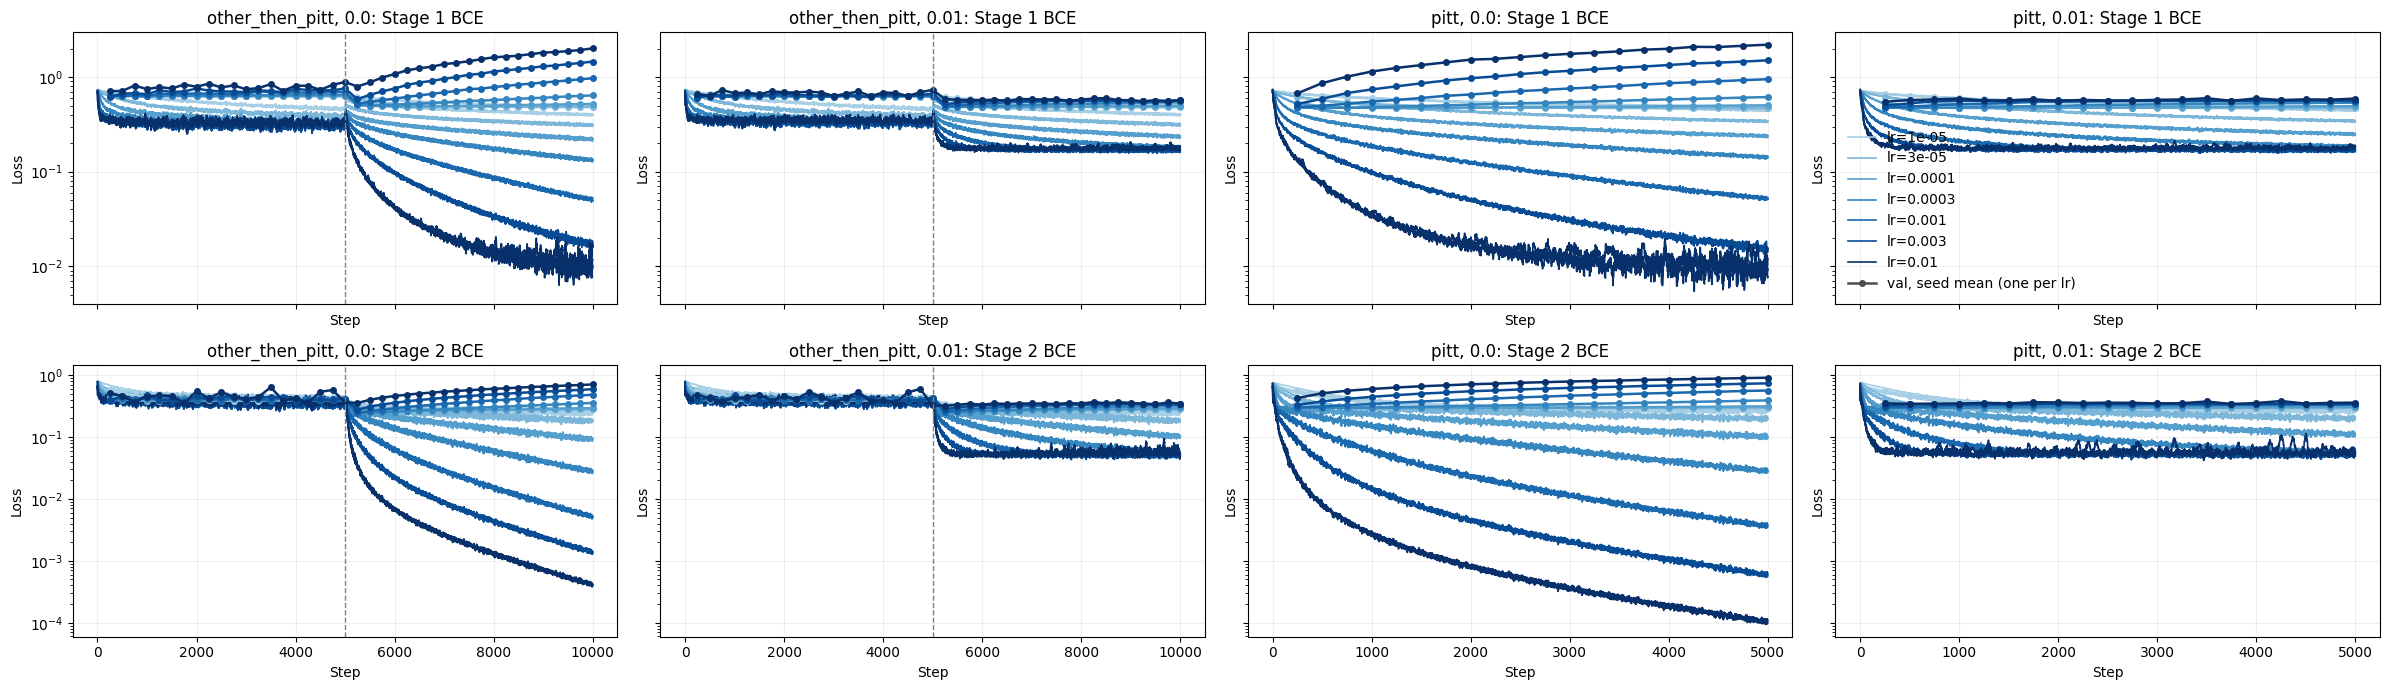

In [31]:
import matplotlib.pyplot as plt

SMOOTH = 25
lrs = sorted(losses.lr.unique())
colors = dict(zip(lrs, plt.cm.Blues(np.linspace(.35, 1, len(lrs)))))
panels = list(zip(losses.groupby(COMPARE), history.groupby(COMPARE)))
fig, axes = plt.subplots(2, len(panels), figsize=(6 * len(panels), 7), sharex="col", sharey="row", squeeze=False)
for row, (stage, val_loss, title) in enumerate([("stage1", "s1_val_loss", "Stage 1 BCE"), ("stage2", "s2_val_loss", "Stage 2 BCE")]):
    for col, ((values, panel), (_, evals)) in enumerate(panels):
        ax = axes[row, col]
        for (lr, seed), g in panel.groupby(["lr", "seed"]):
            ax.plot(g.step, g[stage].rolling(SMOOTH, min_periods=1).mean(), color=colors[lr], lw=1.2,
                    label=f"lr={lr:g}" if seed == panel.seed.min() else None)
        for lr, g in evals.groupby("lr"):
            g = g.groupby("step")[val_loss].mean()
            ax.plot(g.index, g.values, color=colors[lr], lw=1.8, marker="o", ms=4)
        steps = 0
        for split, n in TRAIN_PLANS[panel.train.iloc[0]][:-1]:
            steps += n
            ax.axvline(steps, color="0.5", ls="--", lw=1)
        ax.set_yscale("log")
        ax.grid(alpha=.2)
        ax.set_title(f"{', '.join(map(str, values))}: {title}")
        ax.set_xlabel("Step")
        ax.set_ylabel("Loss")
axes[0, -1].plot([], [], color="0.3", lw=1.8, marker="o", ms=4, label="val, seed mean (one per lr)")
axes[0, -1].legend(frameon=False)
fig.tight_layout()
fig.savefig(RUN_DIR / "loss_curves.png", dpi=150)
plt.show()


## Thresholds

Each head's final checkpoint is scored once, then every `THRESHOLDS` pair is applied to those probabilities, so no
training is repeated. `select` picks the learning rate by precision@K, then each stage's threshold by its own balanced
accuracy, all as means over seeds on val. Ties go to the lower value. `CHOSEN` holds one choice per `COMPARE` value.


In [13]:
def score(entry, split, step=None):
    cfg, ckpts = entry["cfg"], entry["checkpoints"]
    x = pooled(cfg, split)
    head = nn.Linear(x.shape[1], 2).to(device)
    head.load_state_dict(ckpts[step or max(ckpts)])
    return predict(head, x)

def threshold_table(split):
    rows, confusions = [], {}
    for run_id, entry in heads.items():
        p_problem, p_obstacle = score(entry, split)
        for t1, t2 in product(THRESHOLDS, THRESHOLDS):
            m, c = evaluate(data[split], p_problem, p_obstacle, stage_1_threshold=t1, stage_2_threshold=t2)
            rows.append({**entry["cfg"], "run": run_id, "thresh1": t1, "thresh2": t2, **m})
            confusions[run_id, t1, t2] = c
    return pd.DataFrame(rows), confusions

def run_predictions(split, runs):
    def one(run_id):
        cfg = heads[run_id]["cfg"]
        p_problem, p_obstacle = score(heads[run_id], split)
        return data[split][["filename", "class", "source_class"]].assign(
            run=run_id, seed=cfg["seed"], p_problem=p_problem, p_obstacle=p_obstacle, **{k: cfg[k] for k in GROUP})
    return pd.concat([one(run_id) for run_id in runs])

def select(v):
    """Learning rate by ranking, then each stage's threshold by its own metric, all on val means over seeds."""
    lr = v.groupby("lr")[f"precision@{K}"].mean().idxmax()
    v = v[v.lr == lr]
    return lr, v.groupby("thresh1").s1_balanced_accuracy.mean().idxmax(), v.groupby("thresh2").s2_balanced_accuracy.mean().idxmax()

val, val_confusions = threshold_table(EVAL_SPLIT)
val.to_csv(RUN_DIR / "val_thresholds.csv", index=False)
run_predictions(EVAL_SPLIT, heads).to_csv(RUN_DIR / "val_predictions.csv", index=False)
val.groupby(GROUP + ["thresh1", "thresh2"])[METRICS].agg(["mean", "std"]).round(3).to_csv(RUN_DIR / "threshold_summary.csv")
print("Mean stage 1 balanced accuracy over seeds, by stage 1 threshold")
print(val.groupby(GROUP + ["thresh1"]).s1_balanced_accuracy.mean().unstack("thresh1").round(3).to_string())
print("\nMean stage 2 balanced accuracy over seeds, by stage 2 threshold")
print(val.groupby(GROUP + ["thresh2"]).s2_balanced_accuracy.mean().unstack("thresh2").round(3).to_string())

CHOSEN = []
for values, v in val.groupby(COMPARE):
    lr, t1, t2 = select(v)
    CHOSEN.append(dict(zip(COMPARE, values)) | dict(lr=float(lr), thresh1=float(t1), thresh2=float(t2), runs=v[v.lr == lr].run.unique().tolist()))
pd.DataFrame(CHOSEN).to_csv(RUN_DIR / "chosen.csv", index=False)
print("\nChosen on val")
print(pd.DataFrame(CHOSEN).to_string())


Mean stage 1 balanced accuracy over seeds, by stage 1 threshold
thresh1                   0.3    0.5    0.7
train           lr                         
other_then_pitt 0.0001  0.755  0.756  0.764
                0.0003  0.761  0.761  0.738
                0.0010  0.741  0.746  0.750
                0.0030  0.743  0.736  0.747
                0.0100  0.741  0.739  0.742
pitt            0.0001  0.755  0.753  0.749
                0.0003  0.754  0.747  0.740
                0.0010  0.747  0.738  0.730
                0.0030  0.742  0.740  0.737
                0.0100  0.742  0.734  0.741

Mean stage 2 balanced accuracy over seeds, by stage 2 threshold
thresh2                   0.3    0.5    0.7
train           lr                         
other_then_pitt 0.0001  0.651  0.603  0.567
                0.0003  0.625  0.612  0.603
                0.0010  0.624  0.599  0.603
                0.0030  0.624  0.599  0.603
                0.0100  0.611  0.607  0.602
pitt            0.0001  0.604  0.56

Confusion matrices for each `CHOSEN` setting, summed over its seeds at the final step. Rows are truth.


In [32]:
def show_confusion(chosen, confusions):
    keys = [(run_id, chosen["thresh1"], chosen["thresh2"]) for run_id in chosen["runs"]]
    total = lambda name: sum(confusions[k][name] for k in keys)
    print(f"\n=== {({k: v for k, v in chosen.items() if k != 'runs'})}, {len(keys)} seeds ===")
    print(pd.DataFrame(total("s1_cm"), ["clean", "problem"], ["pred clean", "pred problem"]).to_string())
    print(pd.DataFrame(total("s1_by_class"), confusions[keys[0]]["s1_by_class_names"], ["pred clean", "pred problem"]).to_string())
    print(pd.DataFrame(total("s2_cm"), ["Obstacle", "SurfaceProblem"], ["pred Obstacle", "pred SurfaceProblem"]).to_string())
    print(pd.DataFrame(total("pipeline_cm"), [CLEAN, OBSTACLE, SURFACE], ["pred " + n for n in (CLEAN, OBSTACLE, SURFACE)]).to_string())

for chosen in CHOSEN:
    show_confusion(chosen, val_confusions)



=== {'train': 'other_then_pitt', 'lr': 0.0001, 'thresh1': 0.7, 'thresh2': 0.3}, 3 seeds ===
         pred clean  pred problem
clean           630           102
problem         138           276
                                pred clean  pred problem
Crosswalk                               33             0
CurbRamp                               417            39
Obstacle                                18            24
SurfaceProblem                         120           252
no_obstacles                            75            18
no_obstacles_manual_collection         105            45
                pred Obstacle  pred SurfaceProblem
Obstacle                   14                   28
SurfaceProblem             12                  360
                pred clean  pred Obstacle  pred SurfaceProblem
clean                  630              8                   94
Obstacle                18              3                   21
SurfaceProblem         120              6                  246



## Test

The only cell that scores `pitt-test`, and it stays off so a full run can't reach it by accident. It takes each `CHOSEN`
setting as fixed and reports every seed's head, so nothing is picked on test.


In [33]:
RUN_TEST = True                      # set to True once CHOSEN is final

if RUN_TEST:
    test_rows, test_confusions = [], {}
    for chosen in CHOSEN:
        t1, t2 = chosen["thresh1"], chosen["thresh2"]
        for run_id in chosen["runs"]:
            m, c = evaluate(data[TEST_SPLIT], *score(heads[run_id], TEST_SPLIT), stage_1_threshold=t1, stage_2_threshold=t2)
            test_rows.append({**heads[run_id]["cfg"], "run": run_id, "thresh1": t1, "thresh2": t2, **m})
            test_confusions[run_id, t1, t2] = c
    test = pd.DataFrame(test_rows)
    test.to_csv(RUN_DIR / "test_metrics.csv", index=False)
    run_predictions(TEST_SPLIT, test.run.unique()).to_csv(RUN_DIR / "test_predictions.csv", index=False)
    print(f"recall@{K} cap: {test[f'recall@{K}_cap'].iloc[0]:.3f}")
    test_summary = test.groupby(GROUP + ["thresh1", "thresh2"])[METRICS].agg(["mean", "std"]).round(3)
    test_summary.to_csv(RUN_DIR / "test_summary.csv")
    print(test_summary.T.to_string())
    for chosen in CHOSEN:
        show_confusion(chosen, test_confusions)


recall@46 cap: 0.315
train                         pitt        
lr                         0.00001 0.00010
weight_decay                  0.00    0.01
thresh1                        0.3     0.7
thresh2                        0.3     0.3
recall@46             mean   0.272   0.253
                      std    0.004   0.007
precision@46          mean   0.862   0.804
                      std    0.013   0.022
s1_accuracy           mean   0.666   0.796
                      std    0.014   0.003
s1_balanced_accuracy  mean   0.717   0.769
                      std    0.014   0.003
s2_accuracy           mean   0.893   0.858
                      std    0.008   0.004
s2_balanced_accuracy  mean   0.520   0.537
                      std    0.020   0.002
s2_macro_precision    mean   0.780   0.565
                      std    0.291   0.008
s2_macro_recall       mean   0.520   0.537
                      std    0.020   0.002
s2_obstacle_precision mean   0.667   0.231
                      std    0.57